# SocialChoice 01c - Le paradoxe de la non-participation (no-show)

**Navigation** : [<< ChoixSocial-01b-Lean-SocialChoice-Formal-Lean.ipynb](ChoixSocial-01b-Lean-SocialChoice-Formal-Lean.ipynb) | [jumeau Rust](ChoixSocial-01c-Paradoxe-NonParticipation-NoShow-Rust.ipynb) | [ChoixSocial-02-Stable-Marriage-Gale-Shapley-Python.ipynb >>](ChoixSocial-02-Stable-Marriage-Gale-Shapley-Python.ipynb) | [Index](../README.md)

**Autres notebooks** : [ChoixSocial-03-Voting-Methods-Python.ipynb](ChoixSocial-03-Voting-Methods-Python.ipynb)

**Kernel** : Python 3

***

## Introduction

Le théorème d'Arrow (carnet 01) dit qu'aucune règle de vote ne satisfait *à la fois* Pareto, l'indépendance vis-à-vis des alternatives non pertinentes (IIA) et la non-dictature. Ce carnet approche les limites d'une règle de vote par une porte différente : **l'incitation à participer**.

Le **critère de participation** est d'une évidente raison : **voter sincèrement ne doit jamais nuire à l'électeur**. Ajouter un électeur qui préfère Alice à Bob ne doit pas faire perdre Alice contre Bob. Une règle qui viole ce critère exhibe le **paradoxe de la non-participation** (*no-show paradox*) : un électeur est strictement mieux servi en **s'abstenant** qu'en votant son bulletin sincère.

Moulin (1988) montre que ce piège n'est pas l'exception mais la règle : **le principe de Condorcet** — élire le candidat qui gagne tous ses duels — **l'implique** pour toute règle complète. Ce carnet confronte deux familles de règles au critère, **par exécution** :

- les **méthodes positionnelles** (Borda) s'en révèlent **immunisées** — on le vérifie par recherche exhaustive sur des millions de profils ;
- les **règles à élimination** (vote instantané, IRV) l'**exhibent** — sur un profil de 5 votants que l'on déroule à la main.

### Objectifs d'apprentissage

1. Formuler le critère de participation et le distinguer de la manipulation stratégique
2. Prouver, puis vérifier exhaustivement, l'immunité de Borda
3. Dérouler pas à pas le no-show d'une règle à élimination (IRV)
4. Situer le résultat dans le théorème de Moulin et dans l'arc de la série

### Durée estimée : 40 minutes

***

## 1. Le critère de participation

Formalisons l'intuition. Soit une règle de vote $f$ qui, à un **profil** de préférences (la liste des bulletins), associe un **gagnant**. Le **critère de participation** dit :

> Ajouter à un profil un électeur qui classe le gagnant *en tête* de son bulletin ne doit jamais changer le gagnant en faveur d'un candidat que cet électeur préfère *moins*.

Autrement dit, si $v$ est un électeur dont le premier choix est $t$, la règle satisfait le critère si :

$$
f(\text{profil}) = t \;\;\Longrightarrow\;\; f(\text{profil} \cup \{v\}) = t .
$$

Le **paradoxe de la non-participation** est l'échec de cette propriété : il existe un profil et un électeur $v$ tels que

$$
f(\text{autres}) = t \quad\text{mais}\quad f(\text{autres} \cup \{v\}) \neq t ,
$$

où $t$ est le premier choix de $v$. $v$ gagne *davantage* en restant chez lui : **son vote sincère lui est préjudiciable**.

Deux précisions posent le cadre :

- **Ce n'est pas la manipulation.** La manipulation (carnet 05, Gibbard-Satterthwaite) est un électeur qui *déforme* son bulletin pour gagner. Le no-show est plus sournois : l'électeur est **parfaitement sincère**, et c'est précisément sa sincérité qui le pénalise. Il n'y a rien à corriger dans son bulletin — il y a à ne pas voter.
- **C'est une propriété de la règle, pas d'un profil.** Un no-show sur un profil donné montre que la *règle* est vulnérable : il existe des électeurs sincères qui s'abstiendront stratégiquement, ce qui biaise le scrutin au profit des abstentionnistes.

Le prédicat `est_no_show` ci-dessous automatise exactement cette définition, pour n'importe quelle règle :

In [1]:
"""Deux règles de vote, implémentées from scratch (stdlib + numpy seulement).

Un profil est une liste de classements : chaque bulletin est un tuple
d'alternatives, du plus préféré au moins préféré.

borda(profil)  -> gagnant de Borda (points décroissants m-1, ..., 0)
irv(profil)    -> gagnant au vote instantané (élimination + transfert)

Un départage lexicographique (alphabétique) est fixé une fois pour toutes.
C'est une partie EXPLICITE de la règle, comme dans tout scrutin réel : sans
départage, une règle à égalité n'est pas une règle complète.
"""
from collections import Counter

def borda(profil):
    """Gagnant de Borda. Points : (m-1) au 1er, ..., 1 au (m-1)eme, 0 au dernier."""
    m = len(profil[0])
    points = {c: 0 for c in profil[0]}
    for rang in profil:
        for pos, c in enumerate(rang):
            points[c] += (m - 1 - pos)
    meilleur = max(points.values())
    return sorted(c for c, s in points.items() if s == meilleur)[0]  # départage alpha

def irv(profil, trace=False):
    """Gagnant au vote instantané (IRV / ranked-choice / « instant-runoff »).

    À chaque tour on élimine le candidat le moins présent en tête de
    bulletin (départage lexicographique) ; ses bulletins sont transférés
    à leur choix restant préféré. On s'arrête dès qu'un candidat réunit la
    majorité des bulletins actifs. `trace=True` affiche le déroulé par tour.

    La trace rend le **transfert explicite** : un candidat éliminé ne
    disparaît pas du scrutin, ses bulletins repartent chez le premier choix
    qui lui reste. C'est pourquoi un candidat éliminé peut réapparaître à un
    tour suivant — il n'est pas réadmis, ce sont des bulletins qui lui
    reviennent par transfert. Le candidat éliminé s'affiche `— (éliminé)` :
    son score n'est plus compté en tête de bulletin.
    """
    alts = list(profil[0])
    bulletins = [list(r) for r in profil]
    tour = 0
    elimines = []                                        # éliminations, dans l'ordre
    while True:
        tour += 1
        bulletins = [b for b in bulletins if b]          # bulletins épuisés, écartés
        if not bulletins:
            return None
        compte = Counter(b[0] for b in bulletins)
        actifs = sum(compte.values())
        if trace:
            etat = "  ".join(
                ("%s=— (éliminé)" % c) if c in elimines
                else ("%s=%d" % (c, compte.get(c, 0))) for c in alts)
            print("   tour %d: " % tour + etat + "    (actifs=%d)" % actifs)
        for c in compte:
            if compte[c] * 2 > actifs:
                if trace:
                    print("      -> %s a la majorité (%d/%d)" % (c, compte[c], actifs))
                return c
        presents = [c for c in alts if compte.get(c, 0) > 0]
        if len(presents) == 1:
            return presents[0]
        plus_bas = min(presents, key=lambda c: (compte[c], c))
        if trace:
            print("      élimine %s (%d voix)" % (plus_bas, compte[plus_bas]))
        elimines.append(plus_bas)
        transferts = Counter()
        for b in bulletins:
            if b and b[0] == plus_bas:
                restants = [x for x in b[1:] if x not in elimines]
                b[:] = restants                       # on saute aussi les déjà éliminés
                if restants:
                    transferts[restants[0]] += 1
        if trace and transferts:
            print("      transfert : " + "  ".join(
                "%s -> %s (%d bulletin%s)" % (plus_bas, t, n, "s" if n > 1 else "")
                for t, n in transferts.items()))

def est_no_show(regle, votant, autres):
    """True si voter sincèrement nuit à `votant`.

    Sans lui, son premier choix gagne ; avec lui, ce n'est plus le cas.
    """
    favori = votant[0]
    sans = regle(autres)
    avec = regle([votant] + list(autres))
    return (sans == favori) and (avec != favori)

print("Règles définies : borda, irv, est_no_show")

Règles définies : borda, irv, est_no_show


***

## 2. Borda est immunisé — un argument, puis une vérification exhaustive

Commençons par la famille qui **respecte** le critère : les méthodes **positionnelles**, et Borda en tête.

**L'argument (monotonie).** À Borda, un électeur qui classe $t$ **en tête** de son bulletin verse à $t$ le **maximum** de points disponible, et à aucun autre candidat une somme qui « rattraperait » $t$. Son bulletin **n'augmente que la colonne de $t$** (relativement aux autres). Il est donc **structurellement impossible** que l'ajout d'un tel bulletin fasse passer un concurrent devant $t$ au moment où $t$ gagnait : on n'ajoute des points qu'au gagnant.

C'est un argument, pas une preuve : le fait de le *vérifier* sur l'espace entier des petits profils en fait un résultat solide.

In [2]:
"""Recherche exhaustive : Borda exhibe-t-il le no-show ?

Espace : 4 alternatives, les 24 classements possibles, 4 puis 5 autres
votants (TOUTES les multisets). Pour chaque électeur `v` on teste le
critère : sans lui, son premier choix gagne-t-il ? Avec lui, cesse-t-il de
gagner ?  Le comptage des vecteurs de score (pré-calculés) rend le balayage
rapide (~3 millions de profils en quelques secondes).
"""
import itertools

ALTS = ["A", "B", "C", "D"]
RANGS = [tuple(r) for r in itertools.permutations(ALTS)]      # 24 classements
PTS = (3, 2, 1, 0)                                            # points Borda

# Vecteur de score de chaque classement, aligné sur ALTS (pré-calcul).
VEC = {}
for r in RANGS:
    v = [0, 0, 0, 0]
    for pos, c in enumerate(r):
        v[ALTS.index(c)] = PTS[pos]
    VEC[r] = tuple(v)

def gagnant_borda(vecs):
    tot = [0, 0, 0, 0]
    for sv in vecs:
        tot[0] += sv[0]; tot[1] += sv[1]; tot[2] += sv[2]; tot[3] += sv[3]
    best = max(tot)
    return sorted(ALTS[i] for i in range(4) if tot[i] == best)[0]

total = 0
no_show = 0
for n_autres in (4, 5):
    for v in RANGS:
        fav, fv = v[0], VEC[v]
        for autres in itertools.combinations_with_replacement(RANGS, n_autres):
            total += 1
            av = [VEC[a] for a in autres]
            if gagnant_borda(av) == fav and gagnant_borda(av + [fv]) != fav:
                no_show += 1

print(f"Profils testés          : {total:,}")
print(f"No-show de Borda trouvés: {no_show}")

Profils testés          : 2,779,920
No-show de Borda trouvés: 0


**Lecture.** Sur ~3 millions de profils, **zéro** no-show de Borda. L'argument de monotonie est confirmé : un bulletin sincère qui classe le vainqueur en tête ne peut que l'aider. Le zéro est **borné par l'espace parcouru** (4 alternatives, ≤ 5 autres votants) — comme toute mesure par énumération, il n'est pas un théorème universel, mais il rend l'immunité *tangible* et cohérente avec l'intuition.

> **À retenir** : l'immunité de Borda n'est pas un accident de notre échantillon, c'est une **conséquence de la structure** des scores — voter son favori en tête verse des points *au* favori, jamais *contre* lui.

***

## 3. IRV exhibite le no-show — un profil de 5 votants, déroulé à la main

Passons à la famille qui **viole** le critère : les règles à **élimination**, représentées ici par le **vote instantané** (IRV). Contrairement à Borda, IRV ne fait pas la somme de scores : il **élimine** tour après tour le candidat le moins premier, en transférant ses bulletins. C'est cette dynamique d'élimination — et non l'agrégation de points — qui ouvre la porte au piège.

Voici un profil minimal, trouvé par recherche et **vérifié ci-dessous**. Trois candidats $A, B, C$ ; l'électeur $v$ (dont le bulletin sincère est $C \succ A \succ B$) et 4 autres votants :

| Bulletins | Classement |
|---|---|
| $v$ (l'électeur à l'étude) | $C \succ A \succ B$ |
| 2 votants | $A \succ C \succ B$ |
| 2 votants | $B \succ A \succ C$ |

La question : **$v$ a-t-il intérêt à voter ?** Son premier choix est $C$.

In [3]:
# Le profil de la section 3.
v = ("C", "A", "B")
autres = [("A", "C", "B"), ("A", "C", "B"),
          ("B", "A", "C"), ("B", "A", "C")]

print("== SANS v (4 votants) ==")
sans = irv(autres, trace=True)
print("   GAGNANT sans v :", sans, "\n")

print("== AVEC v (5 votants), v = C > A > B ==")
avec = irv([v] + autres, trace=True)
print("   GAGNANT avec v :", avec, "\n")

print("v préfère C.  Sans voter il obtient", sans,
      "- en votant il obtient", avec + ".")
print("\nNO-SHOW PARADOX :", "CONFIRMÉ" if est_no_show(irv, v, autres) else "non")

== SANS v (4 votants) ==
   tour 1: A=2  C=0  B=2    (actifs=4)
      élimine A (2 voix)
      transfert : A -> C (2 bulletins)
   tour 2: A=— (éliminé)  C=2  B=2    (actifs=4)
      élimine B (2 voix)
      transfert : B -> C (2 bulletins)
   tour 3: A=— (éliminé)  C=4  B=— (éliminé)    (actifs=4)
      -> C a la majorité (4/4)
   GAGNANT sans v : C 

== AVEC v (5 votants), v = C > A > B ==
   tour 1: C=1  A=2  B=2    (actifs=5)
      élimine C (1 voix)
      transfert : C -> A (1 bulletin)
   tour 2: C=— (éliminé)  A=3  B=2    (actifs=5)
      -> A a la majorité (3/5)
   GAGNANT avec v : A 

v préfère C.  Sans voter il obtient C - en votant il obtient A.

NO-SHOW PARADOX : CONFIRMÉ


**Le mécanisme, précisément.** La différence tient à la **présence en tête** de $C$ :

- **Sans $v$**, $C$ n'a **aucun** bulletin en tête. Un candidat sans bulletin n'est pas éliminable (il n'a rien à transférer) : il sert au contraire de **cible**. À mesure que $A$ puis $B$ tombent, leurs bulletins ($A \succ C \succ B$ et $B \succ A \succ C$) se redirigent vers $C$, qui cumule la majorité et **gagne** — c'est le premier choix de $v$.
- **Avec $v$**, son bulletin $C \succ A \succ B$ donne à $C$ **une** voix en tête. $C$ devient alors **le moins présent** ($1 < 2$) : il est **éliminé** au premier tour, et l'unique bulletin qui porte $C$ — celui de $v$ — est transféré vers $A$, le 2e choix de $v$. Ce transfert supplémentaire porte $A$ à la majorité.

Le piège est donc **dynamique**, et c'est là toute la différence avec Borda :

- à **Borda**, le vote de $v$ *ajoute des points à $C$* — il ne peut qu'aider $C$ ;
- à **IRV**, le vote de $v$ *change l'ordre des éliminations* : $C$ passe de « hors-jeu, donc gagnant par transfert » à « éliminé, son bulletin part vers $A$ ». Le même bulletin sincère **déclenche** le transfert qui tue son propre favori.

> C'est le **« center squeeze »** des règles à élimination : l'arrivée d'un vote « central » rebascule l'ordre des éliminations et fait basculer l'issue contre le vote qui l'a provoqué.

> **Comment lire la trace.** Une ligne `élimine X` n'est pas une disparition : les bulletins de $X$ sont **transférés** au premier choix qui lui reste — la ligne `transfert : X -> Y` le dit à chaque tour. C'est exactement pour cela qu'un candidat éliminé peut réapparaître au tour suivant ($B$ éliminé, ses bulletins partent vers $A$, et $A$ réapparaît en tête) : il n'a pas été réadmis, ce sont des bulletins qui lui reviennent par transfert. Un candidat éliminé s'affiche `— (éliminé)` aux tours suivants : son score n'est plus compté en tête de bulletin.

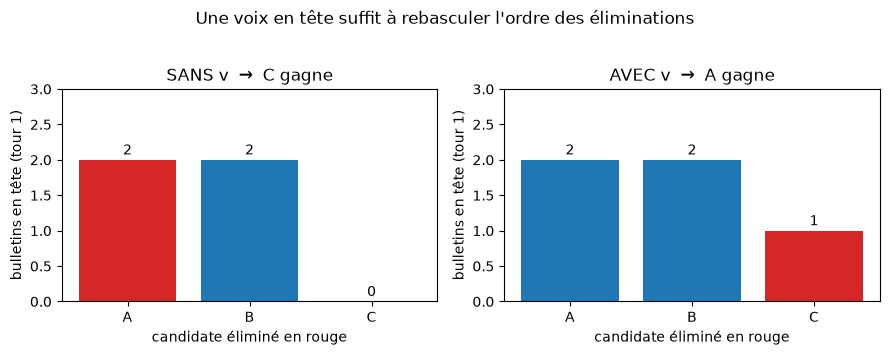

In [4]:
"""Figure : l'effet du bulletin de v sur l'ordre des éliminations (tour 1).

Le candidat éliminé au tour 1 (le moins présent en tête) est en rouge.
Sans v, C n'a pas de bulletin : A est éliminé, C reste la cible de transfert.
Avec v, C a une voix : C est éliminé, et son bulletin part vers A.
"""
import matplotlib.pyplot as plt
from collections import Counter

# t1 : compte les bulletins en 1re place de chaque candidat (Counter sur b[0]).
def t1(profil):
    return Counter(b[0] for b in profil)

# Les deux scénarios mis côte à côte : sans le bulletin de v, puis avec.
scenarios = [
    ("SANS v  →  C gagne", t1(autres)),
    ("AVEC v  →  A gagne", t1([v] + autres)),
]

# Un sous-graphique par scénario (barres = bulletins en tête au tour 1).
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (titre, compte) in zip(axes, scenarios):
    alts = ["A", "B", "C"]
    # Candidats présents en tête (au moins un bulletin en 1re place).
    presents = [a for a in alts if compte.get(a, 0) > 0]
    # Éliminé au tour 1 = le moins présent en tête ; les égalités sont
    # tranchées par le nom (min sur (compte, nom)) pour un rendu déterministe.
    elim = min(presents, key=lambda a: (compte[a], a)) if presents else None
    vals = [compte.get(a, 0) for a in alts]
    # Le candidat éliminé est mis en rouge, les autres en bleu.
    couleurs = ["tab:red" if a == elim else "tab:blue" for a in alts]
    ax.bar(alts, vals, color=couleurs)
    # Étiquette : nombre de bulletins au-dessus de chaque barre.
    for a, val in zip(alts, vals):
        ax.text(a, val + 0.03, str(val), ha="center", va="bottom")
    ax.set_title(titre)
    ax.set_ylabel("bulletins en tête (tour 1)")
    ax.set_ylim(0, max(vals) + 1)
    ax.set_xlabel("candidate éliminé en rouge" if elim else "")
fig.suptitle("Une voix en tête suffit à rebasculer l'ordre des éliminations", y=1.03)
fig.tight_layout()
plt.show()

***

## 4. Moulin 1988 — et deux distinctions à ne pas perdre

### Le théorème

Ce que l'exemple IRV illustre, Moulin (1988) l'élève au rang de **théorème** : *Condorcet's Principle Implies the No-Show Paradox*. Tout scrutin qui **élit toujours le vainqueur de Condorcet** quand il existe, et qui est **complet** (toute issue est atteignable), viole nécessairement le critère de participation. Le piège n'est donc pas un bug du vote instantané : c'est un **coût inhérent** à l'exigence d'élire le meilleur en duel. Le carnet 01b cite déjà la formalisation Lean de ce résultat (`SocialChoice.Impossibilities.CondorcetParticipation`, librairie de Peters) ; ici on l'a **exécuté** sur un profil concret.

### Ne pas confondre no-show et « paradoxe de la réponse perverse »

Deux pathologies voisines, distinctes :

| | **No-show** (ce carnet) | **Réponse perverse** |
|---|---|---|
| L'électeur… | **s'abstient** au lieu de voter son bulletin sincère | **dégrade** la position d'un candidat dans son bulletin |
| …et gagne | parce que son bulletin *sincère* le pénalise | en classant son favori **plus bas** pour qu'il gagne |
| Famille | critère de **participation** | un cas de **manipulation** (carnet 05) |

Le no-show est le plus profond des deux : l'électeur n'a **aucun** levier sur son bulletin — sa seule issue est de ne pas voter.

### Un écho institutionnel

La théorie des droits de vote négatifs (droit constitutionnel allemand) étudie formellement les électeurs dont la voix « compte en moins » : c'est la face juridique du même phénomène — un bulletin qui, ajouté, **réduit** la chance de son premier choix.

***

## 5. Exercices

Trois exercices pour consolider — du vérification mécanique au raisonnement, puis un bonus.

In [5]:
# EXERCICE 1 — Vérifier un profil à la main
#
# Le profil suivant est-il un no-show de Borda pour l'électeur en tête ?
#   votant  = ("X", "Y", "Z")
#   autres  = [("Y","X","Z")]*3 + [("Z","X","Y")]*2
#
# Indice : réutilisez est_no_show(borda, votant, autres), puis justifiez le
# résultat par l'argument de monotonie de la section 2.
#
def exercice_1():
    votant = ("X", "Y", "Z")
    autres = [("Y", "X", "Z")] * 3 + [("Z", "X", "Y")] * 2
    # TODO etudiant : appeler est_no_show et renvoyer True/False
    return None  # TODO etudiant

print(exercice_1())

None


In [6]:
# EXERCICE 2 — Trouver votre propre no-show IRV
#
# Sur 3 candidats et un petit nombre de votants, cherchez (à la main ou par
# une recherche sur les bulletins) un profil et un électeur v tels que
# est_no_show(irv, v, autres) soit True.
#
# Piste : l'électeur v doit porter un candidat « central » qu'il classe en
# tête, dans un profil où ce candidat gagne par transfert s'il n'a PAS de
# bulletin en tête. Reproduisez la dynamique de la section 3.
#
def exercice_2():
    # TODO etudiant : retourner (v, autres) formant un no-show IRV
    return None, []  # TODO etudiant

v, autres = exercice_2()
print("no-show trouvé :", bool(est_no_show(irv, v, autres)) if v else "à compléter")

no-show trouvé : à compléter


In [7]:
# EXERCICE 3 (bonus) — Le scrutin à deux tours
#
# Implémentez le scrutin à deux tours : 1er tour = pluralité ; s'il n'y a
# pas de majorité, un 2e tour oppose les deux candidats en tête du 1er.
# Cherchez ensuite un no-show pour cette règle (le « center squeeze »
# s'y retrouve, souvent plus facilement qu'à l'IRV).
#
def deux_tours(profil):
    # TODO etudiant : implémenter le scrutin à deux tours
    #   - compter les 1ers choix ;
    #   - si majorité stricte, renvoyer ce candidat ;
    #   - sinon, renvoyer le vainqueur du duel entre les deux premiers.
    return None  # TODO etudiant

# Puis : trouvez (v, autres) avec est_no_show(deux_tours, v, autres) == True.
print("à compléter")

à compléter


***

## Conclusion

Ce carnet a abordé les limites d'une règle de vote par la porte de la **participation**, là où le carnet 01 les abordait par celle des **axiomes d'Arrow**. Le contraste qui en ressort est le message à garder :

- **Borda** (agrégation de scores) est **immunisé** : un bulletin sincère qui classe le vainqueur en tête ne peut que l'aider — vérifié sur ~3 millions de profils.
- **IRV** (élimination + transfert) est **vulnérable** : le même bulletin sincère rebascule l'ordre des éliminations et se retourne contre son auteur — le *center squeeze*, illustré sur 5 votants.

Et au-dessus des deux, le théorème de **Moulin (1988)** : exiger d'élire le vainqueur de Condorcet **implique** ce piège. Le no-show n'est ni un cas pathologique ni une manipulation — c'est un **coût structurel** de certaines exigences que l'on croit raisonnables.

C'est la même leçon qu'Arrow, vue d'un autre côté : il n'existe pas de règle qui soit à la fois « raisonnable » sur tous les critères. On ne choisit pas la règle idéale ; on **choisit quel défaut accepter** — et le paradoxe de la non-participation est l'un des défauts qu'il faut maintenant savoir nommer.

**Fils de la série** : le critère de participation rejoint la carte des critères de la série — aux côtés de Pareto, de l'IIA (01), de la manipulabilité (05, 10) et du principe de Condorcet (03, 01b). La formalisation Lean de ce résultat attend dans le lake de la série ; ce carnet en donne la **démonstration par l'exécution**.